# 03 — Exploratory Data Analysis

Explore `../data/ap_clean_2021.csv` (19,416 high schools, 2021) to understand the target and how it relates to school characteristics before modeling.

Roadmap:
1. Inspect the data and the target (`ap_rate`).
2. Target vs. numeric features (poverty, school size, staffing).
3. Target by category (locale, charter / magnet / Title I, state).
4. Geographic view.
5. Feature diagnostics: missingness and correlation.

Note: exploration here is for understanding only. Any preprocessing or feature decisions motivated by these plots should be fit on the **training split only** (notebook `04`) to avoid data leakage.

### importing packages

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv("../data/ap_clean_2021.csv")
df.head()

,ncessch,school_name,leaid,state_location,fips,latitude,longitude,urban_centric_locale,lowest_grade_offered,charter,magnet,title_i_status,enrollment,enrl_9to12,teachers_fte,student_teacher_ratio,free_or_reduced_price_lunch,frl_pct,enrl_AP,ap_rate
0,10000500871,Albertville High School,100005,AL,1,34.262200,-86.204900,32,9.0,0.0,0.0,3.0,1665.0,1665.0,82.0,20.304878,578.0,0.347147,194,0.116517
1,10000600872,Asbury High School,100006,AL,1,34.362500,-86.142000,42,6.0,0.0,0.0,3.0,656.0,365.0,30.0,21.866667,548.0,0.835366,38,0.104110
2,10000600878,Douglas High School,100006,AL,1,34.178658,-86.319462,42,9.0,0.0,0.0,3.0,659.0,659.0,28.0,23.535714,327.0,0.496206,231,0.350531
3,10000600883,Kate D Smith DAR High School,100006,AL,1,34.534948,-86.253261,42,9.0,0.0,0.0,3.0,413.0,413.0,22.0,18.772727,138.0,0.334140,45,0.108959
4,10000601585,Brindlee Mountain High School,100006,AL,1,34.376400,-86.421900,41,6.0,0.0,0.0,3.0,578.0,348.0,26.0,22.230769,293.0,0.506920,111,0.318966


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19416 entries, 0 to 19415
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ncessch                      19416 non-null  int64  
 1   school_name                  19416 non-null  str    
 2   leaid                        19416 non-null  int64  
 3   state_location               19416 non-null  str    
 4   fips                         19416 non-null  int64  
 5   latitude                     19416 non-null  float64
 6   longitude                    19416 non-null  float64
 7   urban_centric_locale         19416 non-null  int64  
 8   lowest_grade_offered         19416 non-null  float64
 9   charter                      18604 non-null  float64
 10  magnet                       13196 non-null  float64
 11  title_i_status               17687 non-null  float64
 12  enrollment                   19416 non-null  float64
 13  enrl_9to12                 

## The target variable: `ap_rate`

`ap_rate` is a proportion in [0, 1], and it is **zero-inflated**: a large share of schools offer no AP at all (rate = 0). We look at the summary stats, the overall distribution, the distribution among schools that *do* offer AP, and the share of exact zeros.

In [7]:
df['ap_rate'].describe()

count    19416.000000
mean         0.130804
std          0.156463
min          0.000000
25%          0.000000
50%          0.087649
75%          0.205301
max          1.000000
Name: ap_rate, dtype: float64

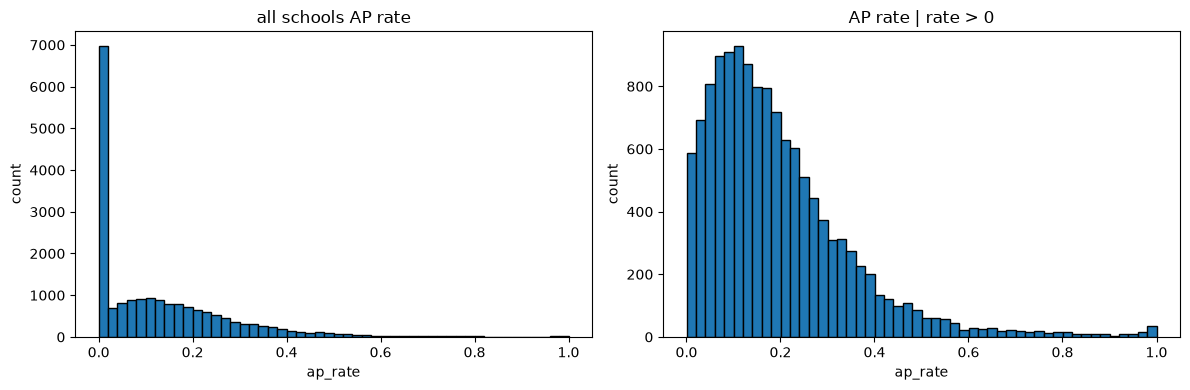

In [10]:
# Zero-inflation is the key feature of this target.
# Left: full distribution (note the tall bar at 0 = schools with no AP).
# Right: only schools that offer AP (rate > 0), which reveals the real shape.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df['ap_rate'], bins=50, edgecolor='black')
ax[0].set(title='all schools AP rate', xlabel='ap_rate', ylabel='count')

nonzero = df.loc[df['ap_rate'] > 0, 'ap_rate']
ax[1].hist(nonzero, bins=50, edgecolor='black')
ax[1].set(title='AP rate | rate > 0', xlabel='ap_rate', ylabel='count')

plt.tight_layout()
plt.show()

schools with no AP (rate = 0): 33.0%
schools offering AP (rate > 0): 67.0%


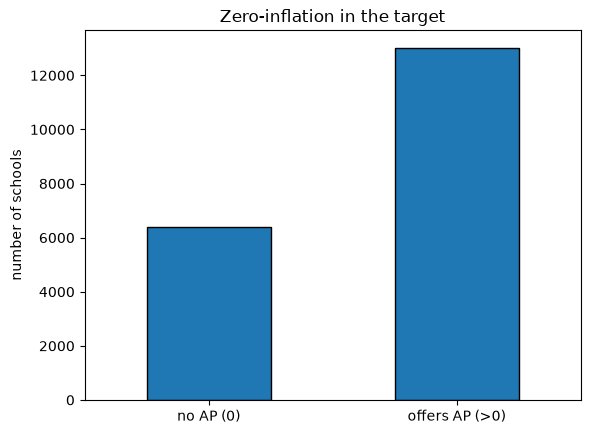

In [11]:
# How much of the target is exactly zero?
zero_share = (df['ap_rate'] == 0).mean()
print(f'schools with no AP (rate = 0): {zero_share:.1%}')
print(f'schools offering AP (rate > 0): {1 - zero_share:.1%}')

counts = pd.Series({'no AP (0)': (df['ap_rate'] == 0).sum(),
                    'offers AP (>0)': (df['ap_rate'] > 0).sum()})
counts.plot.bar(edgecolor='black', rot=0)
plt.title('Zero-inflation in the target')
plt.ylabel('number of schools')
plt.show()

## Target vs. numeric features

Relate `ap_rate` to the continuous school characteristics. With ~19k schools, use hexbin / alpha-blended scatter instead of plain scatter so dense regions stay readable.

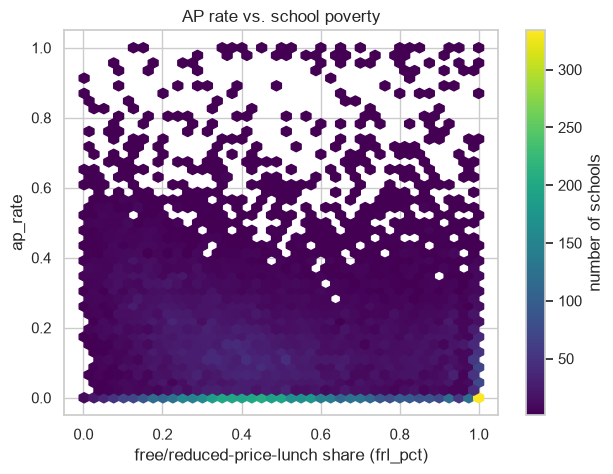

correlation (frl_pct, ap_rate): -0.147


In [15]:
# Equity question: do higher-poverty schools (higher free/reduced-price-lunch
# share) have lower AP participation? Drop rows where frl_pct is missing.
sub = df.dropna(subset=['frl_pct'])

plt.figure(figsize=(7, 5))
plt.hexbin(sub['frl_pct'], sub['ap_rate'], gridsize=40, cmap='viridis', mincnt=1)
plt.colorbar(label='number of schools')
plt.xlabel('free/reduced-price-lunch share (frl_pct)')
plt.ylabel('ap_rate')
plt.title('AP rate vs. school poverty')
plt.show()

print('correlation (frl_pct, ap_rate):',
      round(sub['frl_pct'].corr(sub['ap_rate']), 3))

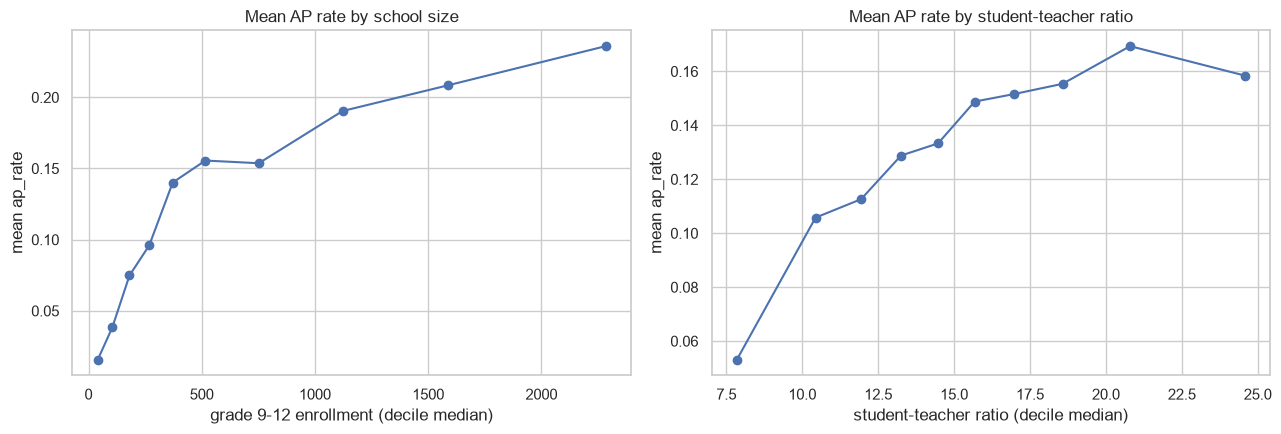

In [25]:
# A raw scatter of 19k zero-inflated points is just a blob, so instead bin each
# feature into deciles (10 equal-sized groups) and plot the MEAN ap_rate per bin.
# Binning by quantile also handles the long tails automatically, so no clipping.
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

def binned_trend(axis, x, title, xlabel):
    d = df[[x, 'ap_rate']].dropna()
    bins = pd.qcut(d[x], q=10, duplicates='drop')
    g = d.groupby(bins, observed=True).agg(
        x_center=(x, 'median'),          # typical feature value in the bin
        mean_ap_rate=('ap_rate', 'mean'))
    axis.plot(g['x_center'], g['mean_ap_rate'], marker='o')
    axis.set(title=title, xlabel=xlabel, ylabel='mean ap_rate')

binned_trend(ax[0], 'enrl_9to12',
             'Mean AP rate by school size', 'grade 9-12 enrollment (decile median)')
binned_trend(ax[1], 'student_teacher_ratio',
             'Mean AP rate by student-teacher ratio',
             'student-teacher ratio (decile median)')

plt.tight_layout()
plt.show()

## Target by category

Compare the target across categorical groups. For a zero-inflated target it helps to look at both the **distribution** (boxplot) and the **share of zeros** within each group.

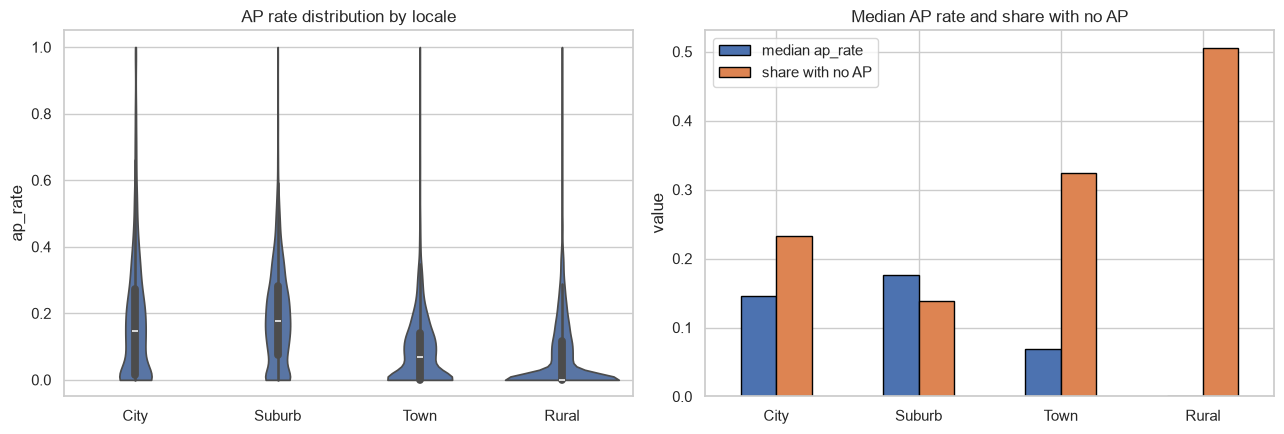

        median_ap_rate  share_zero
locale                            
City             0.146       0.233
Suburb           0.177       0.138
Town             0.069       0.325
Rural            0.000       0.505


In [26]:
# Map the NCES urban-centric locale code to a readable group.
# The code is 2 digits: tens digit = type (1 City, 2 Suburb, 3 Town, 4 Rural),
# ones digit = size/remoteness. // 10 keeps just the type -> 4 groups.
locale_group = {1: 'City', 2: 'Suburb', 3: 'Town', 4: 'Rural'}
df['locale'] = (df['urban_centric_locale'] // 10).map(locale_group)
order = ['City', 'Suburb', 'Town', 'Rural']

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: a violin shows the full distribution shape without flagging every
# high-AP school as an "outlier" the way a boxplot does. cut=0 keeps it in [0, 1].
sns.violinplot(data=df, x='locale', y='ap_rate', order=order, cut=0, ax=ax[0])
ax[0].set(title='AP rate distribution by locale', xlabel='', ylabel='ap_rate')

# Right: the two numbers that matter for a zero-inflated target -
# the typical level (median) and the share of schools with no AP at all.
summary = (df.groupby('locale')
             .agg(median_ap_rate=('ap_rate', 'median'),
                  share_zero=('ap_rate', lambda s: (s == 0).mean()))
             .reindex(order))
summary.plot.bar(ax=ax[1], rot=0, edgecolor='black')
ax[1].set(title='Median AP rate and share with no AP', xlabel='', ylabel='value')
ax[1].legend(['median ap_rate', 'share with no AP'])

plt.tight_layout()
plt.show()

print(summary.round(3))

In [18]:
# For each flag feature, compare the mean AP rate and the share of zeros per group.
for col in ['charter', 'magnet', 'title_i_status']:
    g = df.groupby(col)['ap_rate'].agg(
        n='size',
        mean_ap_rate='mean',
        share_zero=lambda s: (s == 0).mean())
    print(f'--- {col} ---')
    print(g.round(3), '\n')

--- charter ---
             n  mean_ap_rate  share_zero
charter                                 
0.0      16268         0.135       0.287
1.0       2336         0.132       0.507 

--- magnet ---
            n  mean_ap_rate  share_zero
magnet                                 
0.0     12413         0.132       0.313
1.0       783         0.234       0.120 

--- title_i_status ---
                   n  mean_ap_rate  share_zero
title_i_status                                
1.0             2042         0.112       0.345
2.0              696         0.167       0.289
3.0              527         0.062       0.552
4.0             2684         0.094       0.349
5.0             5955         0.115       0.386
6.0             5783         0.162       0.270 



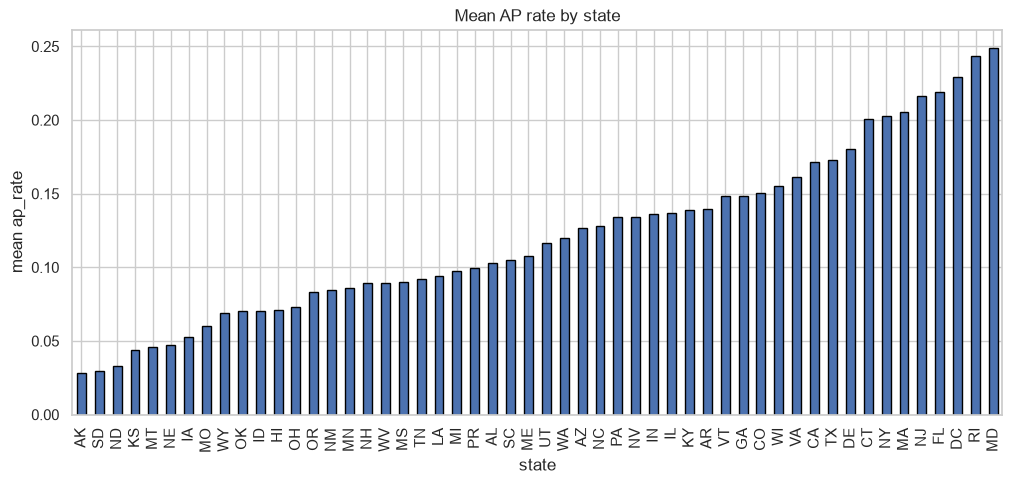

In [19]:
# State-to-state variation (policy, funding). Mean AP rate per state, sorted.
state_means = df.groupby('state_location')['ap_rate'].mean().sort_values()

plt.figure(figsize=(12, 5))
state_means.plot.bar(edgecolor='black')
plt.title('Mean AP rate by state')
plt.ylabel('mean ap_rate')
plt.xlabel('state')
plt.show()

## Geographic view

Each school has coordinates, so we can map the AP rate directly — a quick stand-in for a proper choropleth.

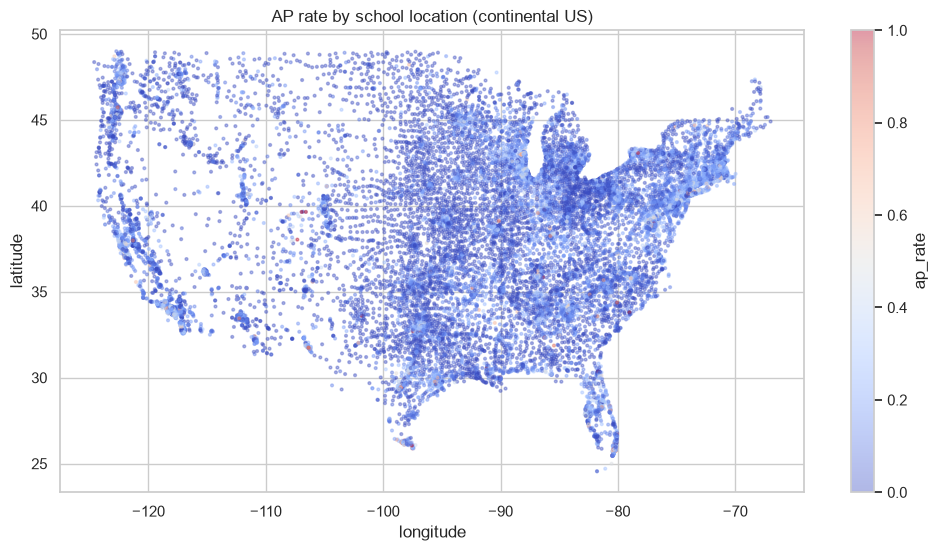

In [23]:
# Scatter schools by location, colored by AP rate. Restrict to the continental
# US window so Alaska / Hawaii / Puerto Rico don't shrink the main map.
m = df[df['longitude'].between(-125, -66) & df['latitude'].between(24, 50)]

plt.figure(figsize=(12, 6))
sc = plt.scatter(m['longitude'], m['latitude'], c=m['ap_rate'],
                 s=4, alpha=0.4, cmap='coolwarm')
plt.colorbar(sc, label='ap_rate')
plt.title('AP rate by school location (continental US)')
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.show()

## Feature diagnostics: missingness and correlation

check which features are missing (and whether it looks systematic) and how the numeric features relate to each other and to the target.

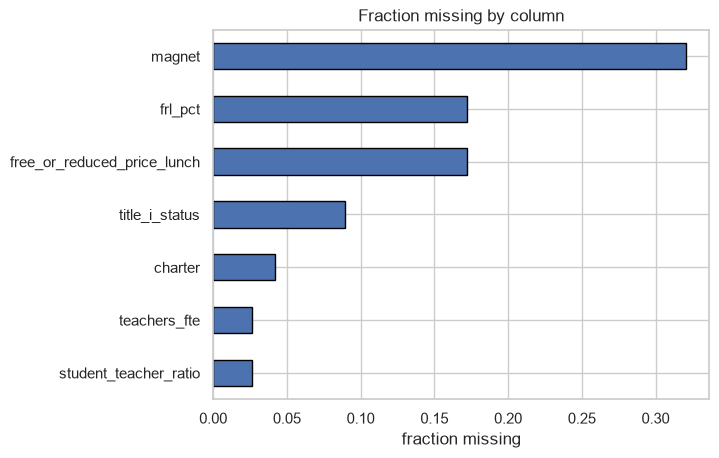

magnet                         0.320
frl_pct                        0.172
free_or_reduced_price_lunch    0.172
title_i_status                 0.089
charter                        0.042
teachers_fte                   0.026
student_teacher_ratio          0.026
dtype: float64


In [21]:
# Fraction missing per column (only columns that have any missing values).
miss = df.isna().mean()
miss = miss[miss > 0].sort_values(ascending=False)

miss.plot.barh(edgecolor='black')
plt.title('Fraction missing by column')
plt.xlabel('fraction missing')
plt.gca().invert_yaxis()
plt.show()
print(miss.round(3))

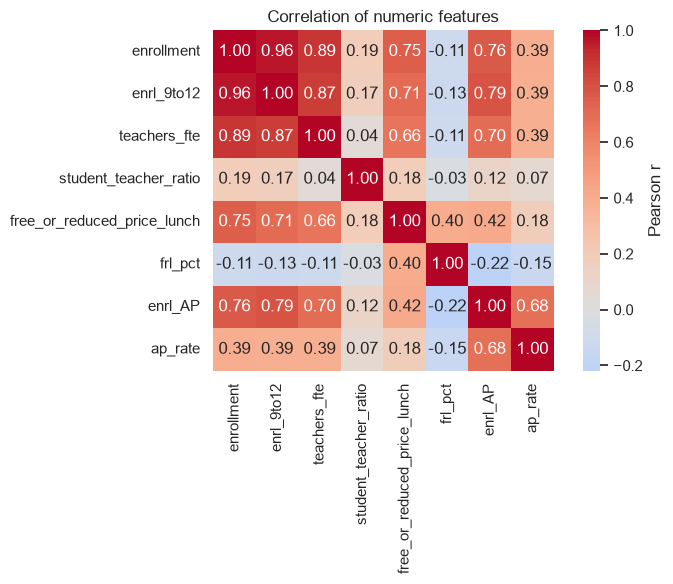

In [22]:
# Correlation among numeric features and the target (spot collinearity + signal).
num_cols = ['enrollment', 'enrl_9to12', 'teachers_fte', 'student_teacher_ratio',
            'free_or_reduced_price_lunch', 'frl_pct', 'enrl_AP', 'ap_rate']
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation of numeric features')
plt.tight_layout()
plt.show()

## Takeaways

The target, `ap_rate`, is not a normal bell curve. About a third of schools have a rate of exactly 0, meaning they don't enroll anyone in AP. For the schools that do offer AP, the rate is skewed right: most sit under 0.2 and a smaller group goes higher. The median is around 0.09 and the mean gets pulled up to 0.13 by that tail. This matters for modeling, because a plain regression isn't really built for a variable with a big spike at zero. I'll probably have to treat "does the school offer AP at all" separately from "how much AP."

Poverty was the clearest pattern. Plotting `ap_rate` against the free/reduced-lunch share, higher-poverty schools sit lower, so poorer schools tend to have less AP. The relationship isn't tight (there's a lot of spread) but the direction is consistent.

Bigger schools have higher AP rates. The binned plot climbs as grade 9-12 enrollment goes up, and the smallest schools are the ones most likely to be at zero, which makes sense since you need enough students to fill an AP class. Student-teacher ratio came out basically flat, so I don't think it says much on its own.

Location matters too. Suburban schools have the highest median and the fewest zeros, while town and rural schools have more schools offering no AP. There's also big variation between states, which is probably more about state policy and funding than about the individual school.

The categorical flags were useful. Magnet schools stand out with a higher average rate (0.23 vs 0.13) and far fewer zeros (12% vs 31%). Charters were the opposite: about half of them offer no AP at all (51% zeros vs 29% for non-charters). For Title I, the non-Title I group (code 6) had the highest average and the schoolwide-eligible-but-no-program group (code 3) the lowest.

On data quality, `magnet` is missing for about 32% of schools and the lunch variables for about 17%. we'll need to deal with that before modeling, either by imputing or by adding a "was missing" flag. we also want to check whether `magnet` is missing more for certain school types, because if it is, just dropping those rows would bias the results.
